# Analysis of trajectories

In [2]:
import json
import os
import pandas as pd
import numpy as np
from tqdm import tqdm
import shutil
from matplotlib import pyplot as plt
import seaborn as sns

while os.path.split(os.getcwd())[-1] != 'calvados-slim':
    os.chdir('..')

from src import curation, utils, constants, visualisation
from src.analysis import slim

## Inspecting available trajectories

In [3]:
# Getting sim dirs
sims = utils.get_scan_dirs('sim/1dp-idp')
sims['Frames'] = (sims.Path + '/' + sims.System + '.dcd').map(utils.get_dcd_frame_count)

# Filtering for unrun or too short simulations
sims = sims[sims['Frames'] > 100]
sims

,System,eps_go,Sampling mode,Replicate,Path,Frames
0,afadin-bcr,0.00,Scan,1,sim/1dp-idp/afadin-bcr/eps_go=0.00/scan/rep1,10000.0
1,afadin-bcr,1.00,Scan,1,sim/1dp-idp/afadin-bcr/eps_go=1.00/scan/rep1,10000.0
2,afadin-bcr,2.00,Scan,1,sim/1dp-idp/afadin-bcr/eps_go=2.00/scan/rep1,10000.0
3,afadin-bcr,3.00,Scan,1,sim/1dp-idp/afadin-bcr/eps_go=3.00/scan/rep1,10000.0
4,afadin-bcr,4.00,Scan,1,sim/1dp-idp/afadin-bcr/eps_go=4.00/scan/rep1,10000.0
...,...,...,...,...,...,...
3311,ywhab-mlxipl,2.75,Scan,1,sim/1dp-idp/ywhab-mlxipl/eps_go=2.75/scan/rep1,10000.0
3312,ywhab-mlxipl,2.85,Scan,1,sim/1dp-idp/ywhab-mlxipl/eps_go=2.85/scan/rep1,10000.0
3313,ywhab-mlxipl,3.00,Scan,1,sim/1dp-idp/ywhab-mlxipl/eps_go=3.00/scan/rep1,10000.0
3314,ywhab-mlxipl,4.00,Scan,1,sim/1dp-idp/ywhab-mlxipl/eps_go=4.00/scan/rep1,10000.0


## Calibrating $Q_{bound}$ per system

In [3]:
Q_bounds_path = 'data/analysis/Q_bounds_calibrated.csv'

if os.path.exists:
    Q_bounds = pd.read_csv('data/analysis/Q_bounds_calibrated.csv', index_col=0).iloc[:,0]

else:
        
    # Looping over systems
    Q_bounds = {}
    for system, subset in tqdm(sims.groupby('System')):

        # Gathering files
        traj_dcds = subset['Path'] + f'/{system}.dcd'
        top_pdb = subset['Path'].iloc[0] + '/top.pdb'
        spec_txt = subset['Path'].iloc[0] + '/specific_interactions.txt'

        # Calculating native contact fraction Q
        contact_dists, contact_eqdists, _ = slim.TwoChain._load_contacts(top_pdb, traj_dcds, spec_txt)
        Q = slim._native_contact_fraction(contact_dists, contact_eqdists)

        # Calibrating Q cutoff for bound state
        Q_bound = slim._bound_q(Q)
        Q_bounds[system] = Q_bound

        # Plotting Q-distribution used for calibrationm both as KDE and histogram
        grid = np.linspace(0,1,501)
        density = slim.gaussian_kde(Q)(grid)
        for plot_type in ['histogram', 'kde']:
            if plot_type == 'histogram':
                dens, bins, _ = plt.hist(Q, bins=np.linspace(0,1,31), density=True)
            elif plot_type == 'kde':
                plt.fill_between(grid, 0, density, linewidth=1)
            xlim = plt.xlim(0,1)
            ylim = plt.ylim(0)
            plt.xticks(np.linspace(0,1,11))
            plt.yticks([])
            plt.vlines(Q_bound, 0, ylim[1]*0.95, color='gray', linewidth=.5, linestyles='dotted', alpha=0.5)
            plt.text(Q_bound+0.02, ylim[1]*0.6, r"$Q_{bound}=" + f"{Q_bound:.3f}"+ "$", fontsize=9, color='gray')
            plt.xlabel(r"Fraction native contacts $Q$")
            plt.ylabel(r"Density $\mathbb{P}(Q)$")
            plt.title(f"System '{system}'")
            plt.text(0.5, ylim[1]*-0.16, r"(concatenated trajectories for $\varepsilon_{\bar{\text{G}}\text{o}} \in (0,1,2,3,4,5)$ kJ/mol", horizontalalignment='center', fontsize=8, color='gray')
            plt.savefig(f'figs/q_densities/concatenated_trajs/{plot_type}/{system}.png', bbox_inches='tight')
            plt.clf()

    Q_bounds = pd.Series(Q_bounds, name='Q_bound')
    Q_bounds.index.name = 'System'
    Q_bounds.to_csv(Q_bounds_path)
Q_bounds

System
afadin-bcr      0.384770
ankra2-ccdc8    0.432866
ankra2-rfx7     0.420842
ap1m1-tgoln2    0.260521
ap2a-amph       0.294589
                  ...   
wdr5-setd1a     0.336673
wdr5-setd1b     0.418838
wds-dgt1        0.288577
wds-nsl1        0.344689
ywhab-mlxipl    0.272545
Name: Q_bound, Length: 276, dtype: float64

## Calculating Kds

In [4]:
# Try to load precalculated dGs
#
# The 'theta' column doubles as a cache marker: any dGs.csv written before the
# single-copy Kd correction (Kd = c_box (1-theta)/theta) lacks it, and is
# discarded rather than silently reused, since every Kd and dG in it is stale.
dGs_path = 'data/analysis/dGs.csv'
cols = ['System', 'eps_go', 'theta', 'Kd', 'Kd_m1sem', 'Kd_p1sem', 'dG', 'dG-1SEM', 'dG+1SEM', 'traj_transitions', 'traj_never_binds', 'traj_never_unbinds']
try:
    dGs = pd.read_csv(dGs_path, index_col=[0,1])
    if 'theta' not in dGs.columns:
        print('dGs.csv predates the Kd correction -- recomputing from scratch')
        dGs = pd.DataFrame(columns=cols).set_index(['System', 'eps_go'])
except FileNotFoundError:
    dGs = pd.DataFrame(columns=cols).set_index(['System', 'eps_go'])

In [6]:
# Looping over systems
for (system, eps_go), subset in tqdm(sims.groupby(['System', 'eps_go'])):

    if (system, eps_go) in dGs.index:
        continue
    
    # Gathering files
    traj_dcds = subset['Path'] + f'/{system}.dcd'
    top_pdb = subset['Path'].iloc[0] + '/top.pdb'
    spec_txt = subset['Path'].iloc[0] + '/specific_interactions.txt'

    # Calculating Kd / dG with blocking error propagation
    Kd, Kd_m1sem, Kd_p1sem, theta, theta_sem = slim.TwoChain.get_kd_sem(top_pdb, traj_dcds, spec_txt, bound_q=Q_bounds[system], verbose=False)
    dG, dG_m1sem, dG_p1sem = slim.dG(Kd), slim.dG(Kd_m1sem), slim.dG(Kd_p1sem)

    # Determining convergence of trajectories; Using best case replicate
    never_binds = True
    never_unbinds = True
    n_binding, n_unbinding = 0,0
    for traj_dcd in traj_dcds:
        bound_state, _ = slim.TwoChain._bound_state(top_pdb, traj_dcd, spec_txt, bound_q=Q_bounds[system])
        n_binding, n_unbinding = slim._state_transitions(bound_state)
        if n_binding > 0:
            never_binds = False
        if n_unbinding > 0:
            never_unbinds = False
        n_binding = max(n_binding, 0)
        n_unbinding = max(n_unbinding, 0)
        
    dGs.loc[(system, eps_go),:] = {
        'System': system,
        'eps_go': eps_go,
        'theta': theta,
        'theta_sem': theta_sem,
        'Kd': Kd,
        'Kd_m1sem': Kd_m1sem,
        'Kd_p1sem': Kd_p1sem,
        'dG': dG,
        'dG-1SEM': dG_m1sem,
        'dG+1SEM': dG_p1sem,
        'traj_transitions': n_binding + n_unbinding,
        'traj_never_binds': never_binds,
        'traj_never_unbinds': never_unbinds
    }

dGs.sort_values(['System', 'eps_go'], inplace=True)
dGs.to_csv('data/analysis/dGs.csv')

100%|██████████| 2421/2421 [25:43<00:00,  1.57it/s] 


## Plotting

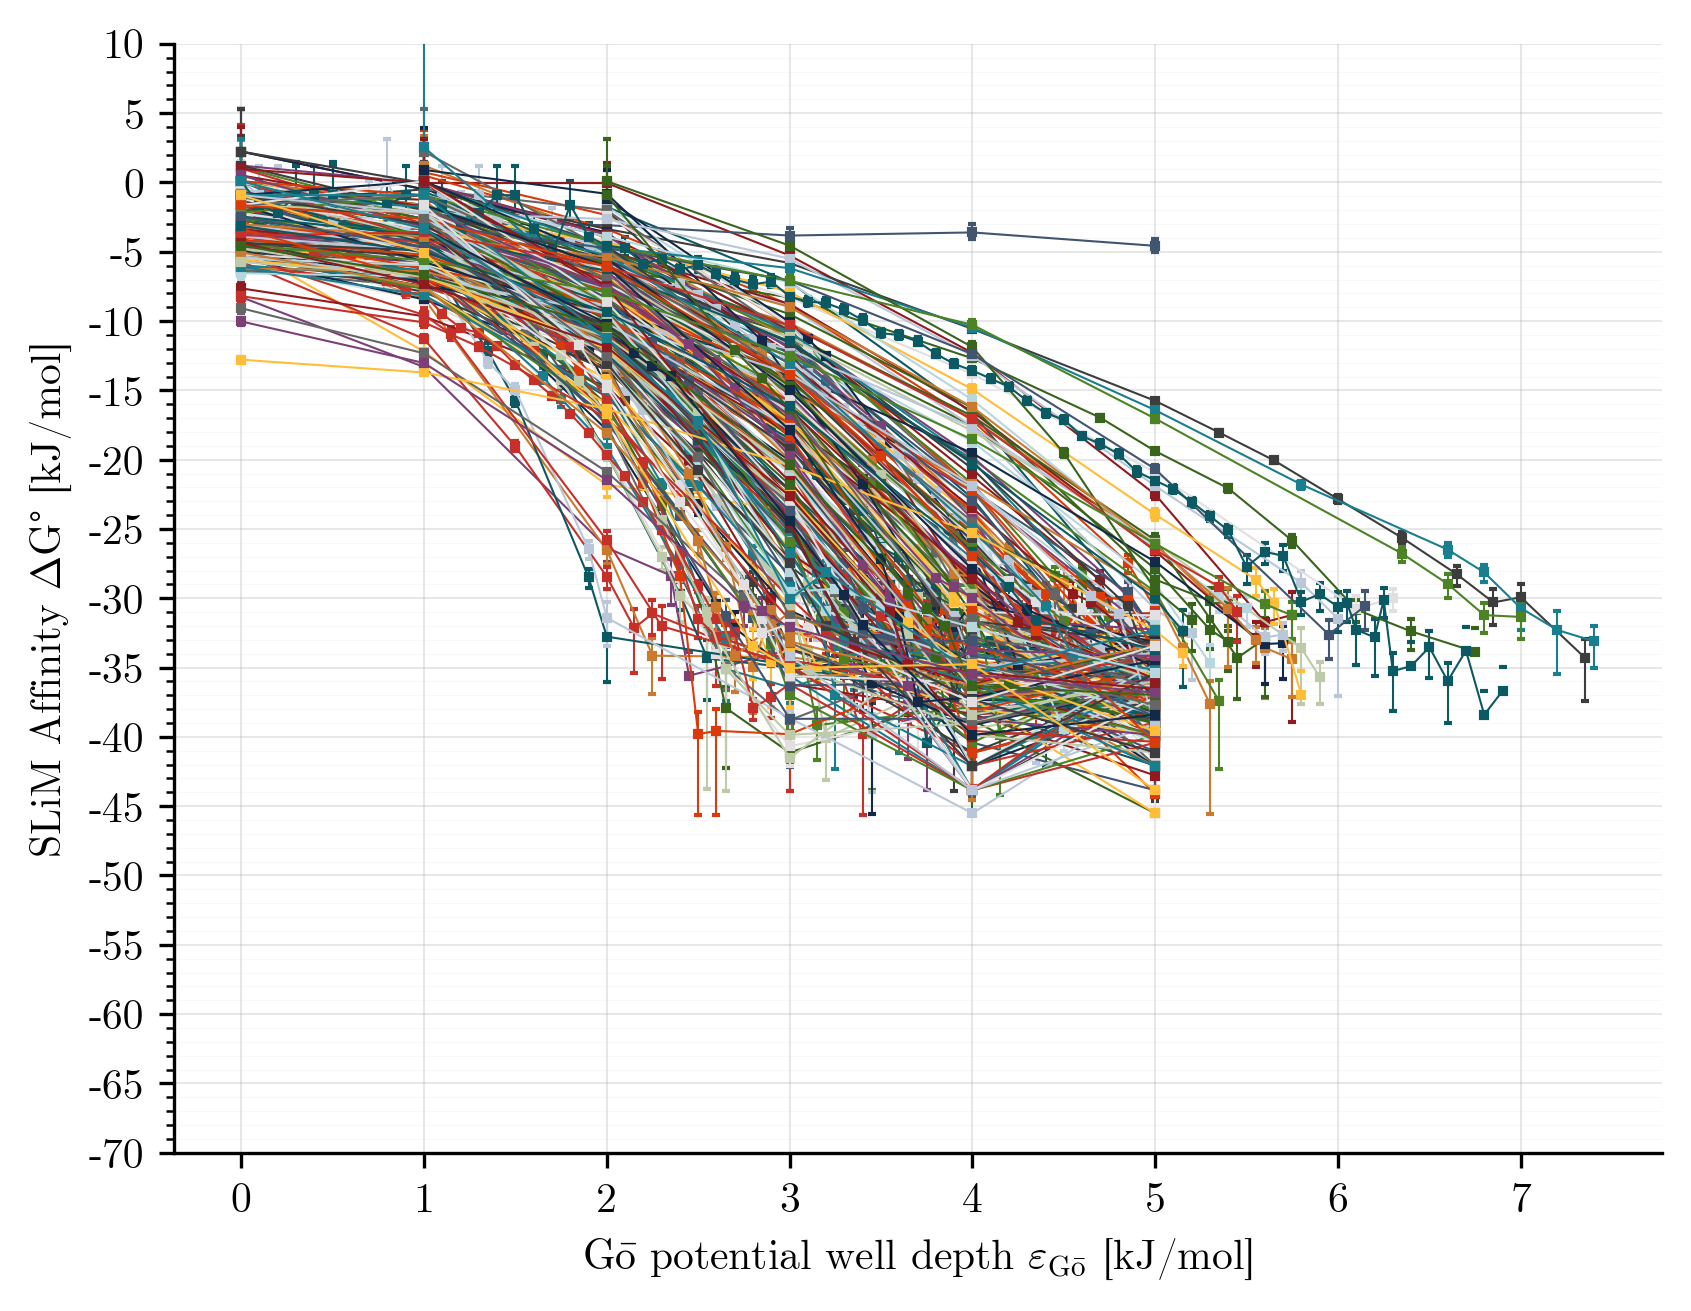

In [7]:
for system, subset in dGs.reset_index().groupby('System'):
    subset = subset[~(subset == np.inf).any(axis=1)]
    #subset = subset[subset['eps_go'].isin(range(6))]
    dG_err = np.stack([subset['dG'] - subset['dG-1SEM'], subset['dG+1SEM'] - subset['dG']])
    plt.errorbar(
        x = subset['eps_go'], y = subset['dG'], yerr = dG_err,
        ms=1.5, capsize=1, elinewidth=0.5, linewidth=0.5, fmt = '-s', 
        label=f"{system}"
    )
plt.ylabel(r'SLiM Affinity ΔG° [kJ/mol]')
plt.xlabel(r'$\text{G}\bar{\text{o}}$ potential well depth $\varepsilon_{\text{G}\bar{\text{o}}}$ [kJ/mol]')
ylim = plt.ylim(-70,10)
plt.yticks(np.arange(ylim[0],ylim[1]+.1,5),minor=False)
plt.yticks(np.arange(ylim[0],ylim[1]+.1,1),minor=True)
plt.grid(which='major', alpha=0.3, linewidth=0.5)
plt.grid(which='minor', alpha=0.1, linewidth=0.2)
#plt.legend(frameon=False, ncol=3, title="System", loc='upper center', bbox_to_anchor=(0.5,-0.15))


/Users/frederikespersenknudsen/Software/Anaconda/anaconda3/envs/calvados/lib/python3.10/site-packages/numpy/core/function_base.py:157: RuntimeWarning: invalid value encountered in multiply
  y *= step
/Users/frederikespersenknudsen/Software/Anaconda/anaconda3/envs/calvados/lib/python3.10/site-packages/numpy/core/function_base.py:167: RuntimeWarning: invalid value encountered in add
  y += start


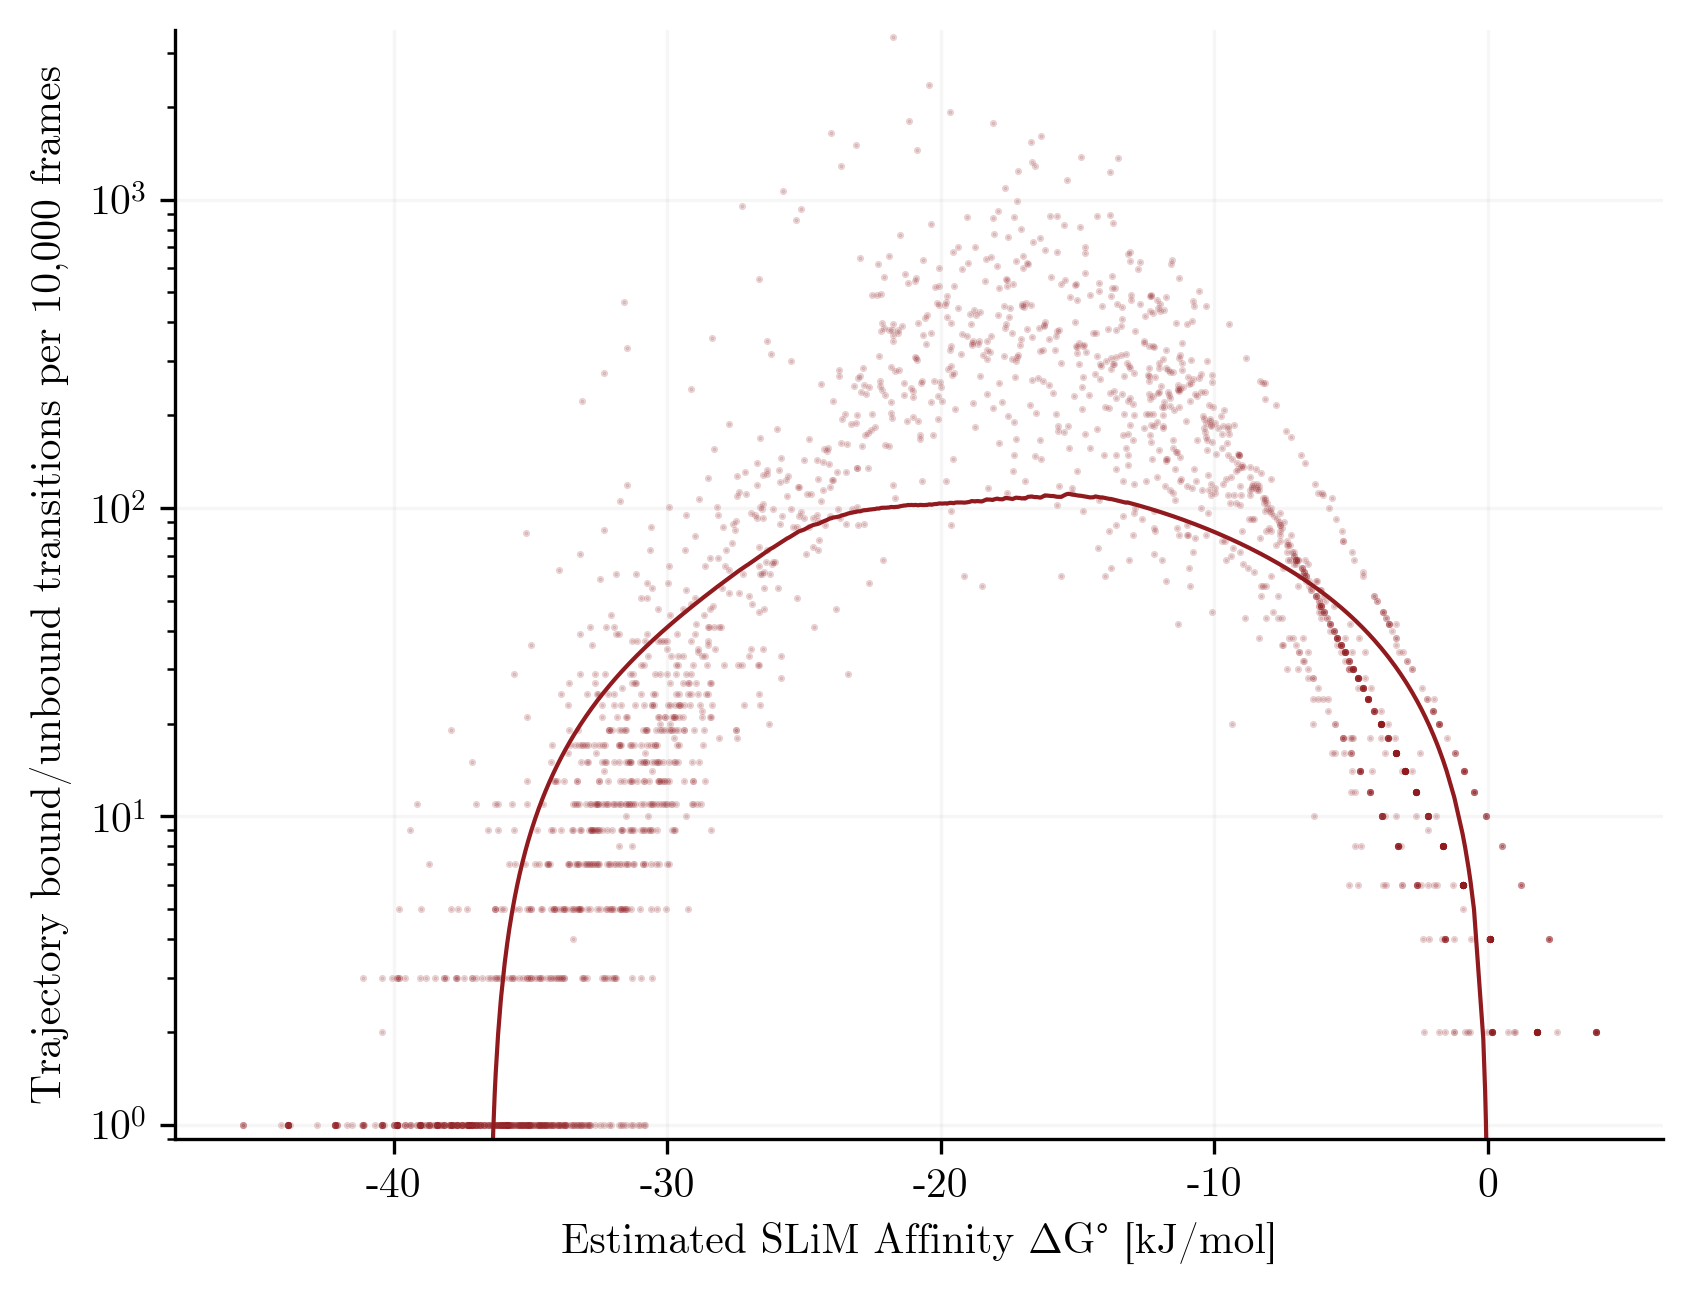

In [8]:
sns.regplot(
    data=dGs,
    x='dG', 
    y='traj_transitions', 
    lowess=True,
    scatter_kws={'s': 0.5, 'alpha': 0.2}, 
    line_kws={'color': visualisation.ku_red, 'lw': 1}
)
plt.ylim(0.9)
plt.xlabel("Estimated SLiM Affinity ΔG° [kJ/mol]")
plt.ylabel("Trajectory bound/unbound transitions per 10,000 frames")
plt.grid(alpha=.1)
plt.yscale('log')